# Temporal memory: simulations and conditional forecasts

Can a history-weighted return model improve on simple price forecasts? This notebook uses the project's **unchanged discrete recurrence**, with a separate layer for conditioning on observed history and calibrating forecasts. It evaluates horizons of 1, 5 and 21 trading sessions at identical origins for every method.

The saved execution uses **synthetic data** and runs offline after installation. It demonstrates the workflow, not market performance. The [2026 market evaluation](docs/results.md) reports both gains and losses against references. Installation is in the [README](README.md); the full [forecast specification](docs/forecasting.md) derives the equations below.

Joint project: **Enia Ardid and Pablo Casado de Amezúa**. The original filename is retained for continuity.

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from temporal_memory import load_prices, synthetic_prices
from run_experiment import export_forecast_run

DATA_DIR = None  # Example: Path("data_finance"); None explicitly selects synthetic data.
OUTPUT = Path("artifacts/notebook")
MAX_PRICES = 1644
TEST_START = None  # None uses the last 30% of returns as the outer test.
# Recorded 2026 market run: use its snapshot, MAX_PRICES = 10000,
# and TEST_START = "2026-01-05". See docs/results.md for the download command.

## 1. Define the available information

For positive prices, log-returns are

$$r_{t,j}=\log\left(P_{t,j}/P_{t-1,j}\right).$$

At origin $o$, forecasts may use only $\mathcal F_o=\sigma(P_0,\ldots,P_o)$ and target $P_{o+h,j}$. Prices are aligned by observed dates; missing interior prices are rejected rather than filled. The [data guide](docs/data.md) specifies the CSV schema and source manifest.

The synthetic generator uses a common Gaussian component and independent sector components, without an imposed long-memory mechanism. Missing local data never causes a silent fallback to synthetic data.

In [2]:
input_hashes = {}
if DATA_DIR is None:
    index_prices, sector_prices = synthetic_prices()
    source = "Synthetic Gaussian prices; 500 observations; seed 17; not market data."
    label = "Synthetic demonstration · 11 sectors · no market-performance claim"
else:
    DATA_DIR = Path(DATA_DIR)
    index_prices, sector_prices = load_prices(DATA_DIR)
    manifest = DATA_DIR / "source.json"
    source = json.loads(manifest.read_text()) if manifest.exists() else "Local CSVs; provider and adjustment convention unverified."
    input_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in (DATA_DIR / "raw").glob("*.csv")}
    label = (source.get("provider", "Local CSV experiment") + " · recorded data snapshot"
             if isinstance(source, dict) else "Local CSV experiment · provenance unverified")

index_prices = index_prices.iloc[-MAX_PRICES:]
sector_prices = sector_prices.iloc[-MAX_PRICES:]
print(source)
print(f"Aligned prices: {len(index_prices)}; {index_prices.index[0].date()} to {index_prices.index[-1].date()}")
print("Assets:", ", ".join(sector_prices.columns))
display(index_prices.head())

Synthetic Gaussian prices; 500 observations; seed 17; not market data.
Aligned prices: 500; 2020-01-01 to 2021-11-30
Assets: XLB, XLE, XLF, XLI, XLK, XLP, XLRE, XLU, XLV, XLY, XLC


,SP500
2020-01-01,3000.000000
2020-01-02,3002.543347
2020-01-03,2962.866412
2020-01-06,2976.093745
2020-01-07,3007.375423


## 2. Preserve the return model

The Grünwald–Letnikov binomial weights satisfy

$$w_{0,j}=1,\qquad w_{k,j}=\left(1-\frac{\alpha_j+1}{k}\right)w_{k-1,j}.$$

The unit-step recurrence is

$$\mathbf r_t=\boldsymbol\mu+\boldsymbol\varepsilon_t+\kappa L\mathbf r_{t-1}
+\sum_{k=0}^{t-1}W_k(\mathbf r_{t-1-k}-\mathbf c),\qquad
W_k=\operatorname{diag}(w_{k,1},\ldots,w_{k,J}).$$

Innovations are independent across dates and assets, with $\boldsymbol\varepsilon_t\sim\mathcal N(\mathbf0,D)$ and $D=\operatorname{diag}(\sigma_1^2,\ldots,\sigma_J^2)$. The index uses $\mathbf c=\mathbf0$ and $\kappa=0$; sectors use $\mathbf c=\boldsymbol\mu$ and the original reflected-neighbor Laplacian. Their ordering is estimated from past correlations.

The original Hurst mapping is retained:

$$\alpha_j=\operatorname{clip}\left(\frac12+s\left(H_j-\frac12\right),0.05,0.95\right),
\qquad s=1\ \text{for the index},\quad s=0.6\ \text{for sectors}.$$

This is a **discrete modeling heuristic**, not a verified discretization of the paper's fractional PDE. The [scientific review](docs/scientific_review.md) explains the sign, lag and chain-rule discrepancies. Improving forecast evaluation does not remove those limitations.

## 3. Compute a conditional forecast

The new forecast starts from all observed returns through the origin and anchors prices at $P_o$. It does not fit to a future endpoint. With fixed parameters, future cumulative log-returns are Gaussian. Their mean $m_{h,j}$ follows the same recurrence with future innovations set to zero.

Uncertainty propagates through impulse-response matrices:

$$B_\ell=W_{\ell-1}+\mathbf1_{\{\ell=1\}}\kappa L,\qquad
A_0=I,\qquad A_q=\sum_{\ell=1}^{q}B_\ell A_{q-\ell},\qquad
C_q=\sum_{v=0}^{q}A_v.$$

$$\Sigma_h=\sum_{q=0}^{h-1}C_qDC_q^{\mathsf T},\qquad v_{h,j}=(\Sigma_h)_{jj}.$$

The raw memory forecast is the exact expected price under the fitted model:

$$\widehat P^{\mathrm{memory}}_{o+h,j}=P_{o,j}\exp\left(m_{h,j}+\tfrac12v_{h,j}\right).$$

The variance term matters: exponentiating the mean log-price gives a median, not a mean. Exact moments remove Monte Carlo sampling noise while keeping the recurrence unchanged. The raw 10–90% intervals omit parameter uncertainty; they are not calibrated intervals for the blended forecast.

## 4. Select calibration before the outer test

The drift reference and calibrated point forecast are

$$\widehat P^{\mathrm{drift}}_{o+h,j}=P_{o,j}e^{h\widehat\mu_j},\qquad
\widehat P^{\mathrm{cal}}_{o+h,j}=\lambda_h\widehat P^{\mathrm{memory}}_{o+h,j}
+(1-\lambda_h)\widehat P^{\mathrm{drift}}_{o+h,j}.$$

At internal validation origins, normalize targets and forecasts by their origin prices. With target $y_i$, memory forecast $a_i$ and drift forecast $b_i$, choose

$$\widehat\lambda_h=\operatorname{clip}\left(
\frac{\sum_i(a_i-b_i)(y_i-b_i)}{\sum_i(a_i-b_i)^2},0,1\right).$$

Use zero when the denominator vanishes. Sectors share one weight per horizon; the index is calibrated separately. The coupling-scale grid remains $\{0,0.5,1\}$ times the training-correlation scale. This is an explicit external calibration layer. **A zero memory weight selects the drift reference; its performance cannot be credited to memory.**

Internal expanding validation origins occupy the last 40% of development data, spaced 21 observations apart. After selecting the weight and coupling scale, freeze them. Outer origins advance every five observations. Parameters are refitted from observed history at least 21 observations apart, hence every 25 with this origin spacing. Earlier test observations may enter later fits only after they become available.

index: development through 2021-05-04; 26 outer origins; 6 parameter refits
sectors: development through 2021-05-04; 26 outer origins; 6 parameter refits


,model,horizon,kappa_scale,memory_weight,validation_mse,drift_mse
0,index,1,0.0,0.059246,0.000021,0.000022
1,index,5,0.0,0.000000,0.000107,0.000107
2,index,21,0.0,0.000000,0.001918,0.001918
3,sectors,1,1.0,0.077516,0.000051,0.000051
4,sectors,5,0.0,0.000000,0.000277,0.000277
5,sectors,21,0.0,0.000000,0.002564,0.002564


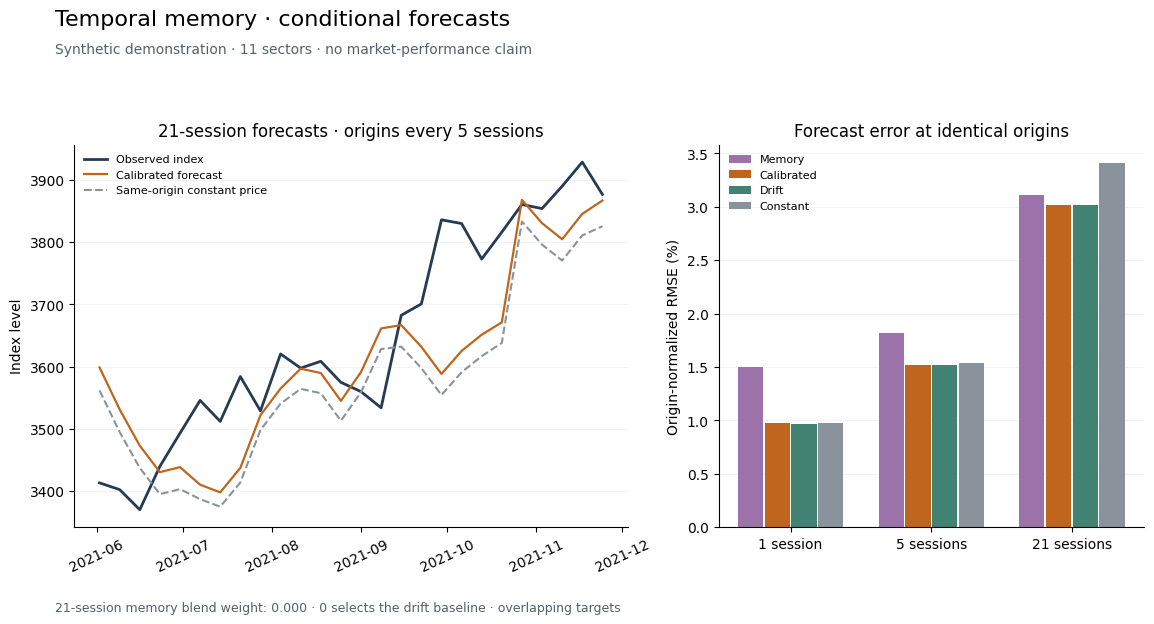

In [3]:
metrics_table, forecasts, figure = export_forecast_run(
    index_prices, sector_prices, OUTPUT, source, label, input_hashes,
    test_start=TEST_START,
)
summary = json.loads((OUTPUT / "forecast_summary.json").read_text())
choices = pd.read_csv(OUTPUT / "calibration_choices.csv")
for name, run in summary["runs"].items():
    print(f"{name}: development through {run['development_end']}; "
          f"{run['test_origins']} outer origins; {run['refits']} parameter refits")
display(choices[["model", "horizon", "kappa_scale", "memory_weight", "validation_mse", "drift_mse"]].round(6))
display(figure)
plt.close(figure)

## 5. Compare every method on the same targets

The constant-price reference is $\widehat P^{\mathrm{constant}}_{o+h,j}=P_{o,j}$. Errors are normalized by the origin price:

$$\operatorname{rRMSE}_{h,j}=100\sqrt{\frac1{N_h}\sum_o
\left(\frac{\widehat P_{o+h,j}-P_{o+h,j}}{P_{o,j}}\right)^2}.$$

The skill score is $1-\operatorname{MSE}_{\mathrm{method}}/\operatorname{MSE}_{\mathrm{constant}}$, using those normalized errors. Positive skill means improvement on that reference in this sample. Negative scores and losses remain visible.

All three horizons use the same origins, with complete targets. The 21-session target intervals overlap, so their errors are not independent. High price-level $R^2$ is not sufficient evidence of forecasting skill.

In [4]:
index_scores = metrics_table.xs("SP500", level="asset")
display(index_scores[["origins", "RMSE", "relative_RMSE_percent", "skill_vs_constant", "memory_weight"]].round(4))
sector_scores = metrics_table.loc[metrics_table.index.get_level_values("asset") != "SP500"]
display(sector_scores["relative_RMSE_percent"].unstack("method").round(4))

origins      RMSE  relative_RMSE_percent  \
horizon method                                                 
1       memory           26   53.4107                 1.5008   
        calibrated       26   34.7673                 0.9761   
        drift            26   34.3753                 0.9648   
        constant         26   34.7193                 0.9743   
5       memory           26   64.7403                 1.8191   
        calibrated       26   54.2901                 1.5142   
        drift            26   54.2901                 1.5142   
        constant         26   55.0562                 1.5349   
21      memory           26  110.5793                 3.1090   
        calibrated       26  107.0728                 3.0207   
        drift            26  107.0728                 3.0207   
        constant         26  121.2475                 3.4120   

                    skill_vs_constant  memory_weight  
horizon method                                        
1       memory                -1.3724            NaN  
        calibrated            -0.0036         0.0592  
        drift                  0.0195            NaN  
        constant               0.0000            NaN  
5       memory                -0.4045            NaN  
        calibrated             0.0268         0.0000  
        drift                  0.0268            NaN  
        constant               0.0000            NaN  
21      memory                 0.1697            NaN  
        calibrated             0.2162         0.0000  
        drift                  0.2162            NaN  
        constant               0.0000            NaN

method         calibrated  constant   drift  memory
asset horizon                                      
XLB   1            1.1573    1.1502  1.1408  1.7271
      5            2.4219    2.4081  2.4219  2.8943
      21           5.0717    5.2515  5.0717  5.1572
XLC   1            1.1214    1.1301  1.1137  1.5168
      5            2.0936    2.1518  2.0936  2.4710
      21           4.3699    5.1179  4.3699  4.5502
XLE   1            1.1558    1.1534  1.1434  1.6344
      5            2.0732    2.1144  2.0732  2.7238
      21           5.3610    5.6712  5.3610  5.5682
XLF   1            1.1986    1.2142  1.2159  1.4190
      5            2.0326    2.0661  2.0326  2.8160
      21           4.3728    4.9427  4.3728  4.6771
XLI   1            1.0011    0.9981  0.9926  1.5420
      5            1.8388    1.8487  1.8388  2.0854
      21           3.2025    3.5643  3.2025  3.1108
XLK   1            1.1192    1.0981  1.0999  1.7368
      5            1.7493    1.7420  1.7493  2.0326
      21           3.6722    3.5816  3.6722  3.8459
XLP   1            0.8858    0.8929  0.8890  1.3269
      5            1.9314    1.9703  1.9314  2.2708
      21           3.8412    4.3587  3.8412  3.8827
XLRE  1            1.3191    1.3033  1.2931  2.0276
      5            2.0371    2.0040  2.0371  2.6548
      21           4.0191    4.0232  4.0191  4.1713
XLU   1            1.1993    1.1655  1.1687  1.8728
      5            2.2956    2.2846  2.2956  2.6914
      21           4.2462    4.1130  4.2462  4.1853
XLV   1            1.1123    1.1069  1.0966  1.5909
      5            1.3084    1.3046  1.3084  1.9854
      21           2.0422    2.0486  2.0422  2.0889
XLY   1            1.1590    1.1461  1.1359  1.8088
      5            2.0246    2.0072  2.0246  2.3751
      21           2.5279    2.7690  2.5279  2.3683

## Interpretation and reproducibility

The saved synthetic execution verifies the workflow. For financial conclusions, inspect the [recorded 2026 backtest](docs/results.md): calibration reduces one-session raw-memory error, but gains over simple references are small. At five and 21 sessions, validation selects the drift reference completely. The raw model wins at 21 sessions on the test sample; the frozen selection is not changed afterward.

The exporter saves predictions with their origins, targets and last fitting dates, metrics, validation scores, selected weights, full parameter refits, input hashes and a core-file hash. These local artifacts make the run auditable. Raw market data are not bundled. A newly downloaded adjusted-price snapshot may differ from the recorded one.

The earlier Monte Carlo simulation and illustrative buy-and-hold basket comparison remain available without changing their core:

```bash
python run_experiment.py --mode simulation --synthetic --output artifacts/simulation
python -m unittest discover -s tests -v
```

See the [retained simulation specification](docs/methodology.md) for its equations and [publication notes](docs/publication.md) for the remaining manuscript and release decisions. These experiments do not establish a fractional continuous-time limit, general predictive superiority or profitable trading.

In [5]:
print("Core SHA-256:", summary["core_sha256"])
print("Forecast artifacts:")
for filename in ["forecasts.csv", "forecast_metrics.csv", "validation_scores.csv",
                 "calibration_choices.csv", "forecast_summary.json", "forecast_fits.json",
                 "forecast_overview.png"]:
    print(" ", OUTPUT / filename)

Core SHA-256: e04cd911683a91f4df6fa3b0d05690b640505b696730d17fc44f7350d171ce6f
Forecast artifacts:
  artifacts/notebook/forecasts.csv
  artifacts/notebook/forecast_metrics.csv
  artifacts/notebook/validation_scores.csv
  artifacts/notebook/calibration_choices.csv
  artifacts/notebook/forecast_summary.json
  artifacts/notebook/forecast_fits.json
  artifacts/notebook/forecast_overview.png


## 6. Adaptive research extension: learn a correction and test its value

The original recurrence above remains unchanged. A separate head now learns a signed correction from its forecasts and recent-return controls. For simple forward return $y_{o,h,j}=P_{o+h,j}/P_{o,j}-1$ and drift reference $b_{o,h,j}$, solve

$$\min_{a,\boldsymbol\beta}\frac1N\sum_i
(y_i-b_i-a-\mathbf z_i^{\mathsf T}\boldsymbol\beta)^2+\eta\lVert\boldsymbol\beta\rVert_2^2.$$

Standardization uses training rows only. A label from origin $u$ is available at $o$ only when $u+h\le o$; this boundary also applies to candidate selection. Four candidates combine penalties $\eta\in\{1,10\}$ with windows of 504 or 1,008 observations. Choose among them, constant price and drift using previously issued forecasts whose outcomes have matured. A separate **without-memory ablation** repeats the same process without memory predictors.

The [full adaptive specification](docs/adaptive_forecasting.md) defines all features, the chronology and the finite candidate set. The market evaluation covers every year from 2023 through 2026; it is exploratory because these historical data were already available. The new point predictor is experimental: its pooled error does not beat drift consistently.

This extension needs more history for fitting and selection. The synthetic example below uses **900 prices**; for market inputs it reloads the full aligned snapshot, without applying the earlier `MAX_PRICES` cap.

**Estimation note:** Some Hurst-estimation RANSAC trials emit an undefined-$R^2$ warning for tiny internal subsets. This concerns the estimator's internal fits, not the number of evaluated forecasts. Warning messages are retained below; local environment paths in the saved output are redacted for publication.

index: generating causal features and fitting forecast heads...


sectors: generating causal features and fitting forecast heads...


<virtual-environment>/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


<virtual-environment>/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1283: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


,horizon,method,origins,relative_RMSE_percent,skill_vs_constant
10,1,adaptive,46,0.8276,0.0030
11,1,without_memory,46,0.8289,-0.0002
12,1,raw_memory,46,1.0910,-0.7328
13,1,drift,46,0.8315,-0.0066
14,1,constant,46,0.8288,0.0000
25,5,adaptive,46,1.9579,-0.0470
26,5,without_memory,46,1.9599,-0.0492
27,5,raw_memory,46,2.2194,-0.3454
28,5,drift,46,1.9444,-0.0326
29,5,constant,46,1.9134,0.0000


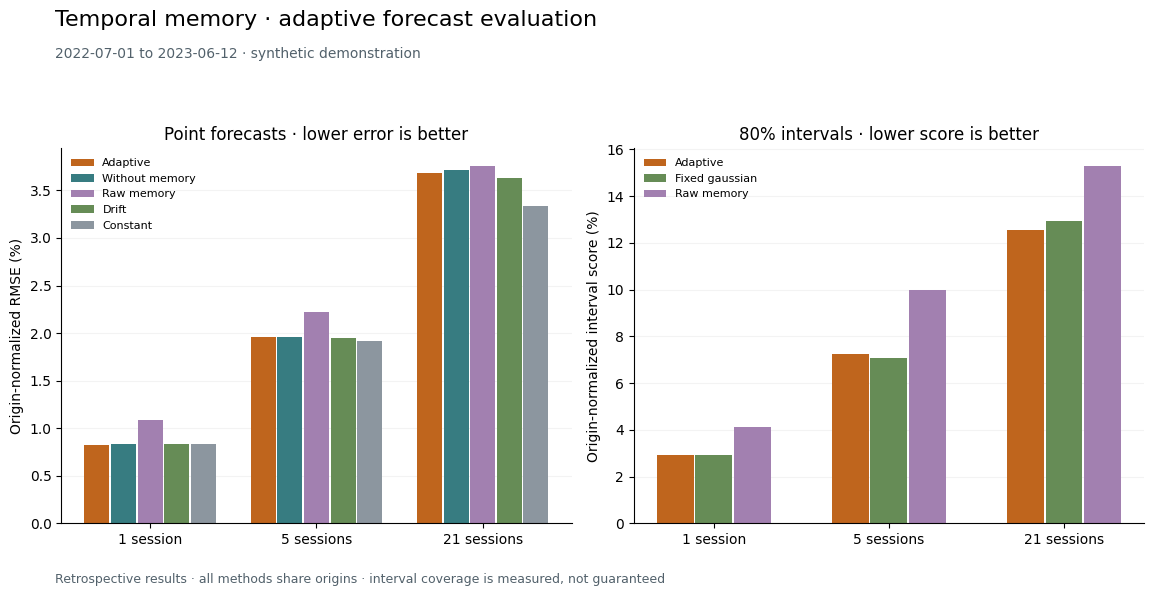

In [6]:
from run_adaptive import export_adaptive_run

ADAPTIVE_OUTPUT = Path("artifacts/notebook-adaptive")
if DATA_DIR is None:
    adaptive_index, adaptive_sectors = synthetic_prices(900)
    adaptive_source = "Synthetic Gaussian prices; 900 observations; seed 17; not market data."
    report_start = str(adaptive_index.index[650].date())
else:
    adaptive_index, adaptive_sectors = load_prices(DATA_DIR)
    adaptive_source = source
    report_start = "2023-01-01"

adaptive_metrics, adaptive_intervals, latest, adaptive_figure = export_adaptive_run(
    adaptive_index, adaptive_sectors, ADAPTIVE_OUTPUT, adaptive_source, report_start, input_hashes,
)
display(adaptive_metrics[(adaptive_metrics.asset == "SP500") & (adaptive_metrics.year == "all")]
        [["horizon", "method", "origins", "relative_RMSE_percent", "skill_vs_constant"]].round(4))
display(adaptive_figure)
plt.close(adaptive_figure)

## 7. Evaluate uncertainty and record unscored forecasts

The adaptive scale tracks changing return volatility:

$$v_{o,j}=0.94v_{o-1,j}+0.06r_{o,j}^2,\qquad s_{o,h,j}=\sqrt{hv_{o,j}}.$$

A nominal 80% interval uses the upper empirical 80th percentile $q$ of matured absolute forecast errors divided by their original scales:

$$\left[P_{o,j}\max(0,1+\widehat y_{o,h,j}-q s_{o,h,j}),\;
P_{o,j}(1+\widehat y_{o,h,j}+q s_{o,h,j})\right].$$

These are empirical intervals without a distribution-free coverage guarantee. The interval score penalizes width and missed outcomes; smaller is better. Comparing with fixed-Gaussian intervals around the same point forecast isolates the interval construction. A raw-memory interval also has a different center.

The [recorded market evaluation](docs/adaptive_results.md) finds index coverage of approximately 79–82% and better interval scores, while retaining the point model's losses to drift. Read the synthetic scores below as an execution example only.

The latest forecasts use the final observed price and are **unscored**. Horizons are trading observations; future exchange-calendar dates are not guessed. Each execution writes a new timestamped local issuance record, allowing evaluation after outcomes become available. It does not constitute independently certified public timestamping.

In [7]:
display(adaptive_intervals[(adaptive_intervals.asset == "SP500") & (adaptive_intervals.year == "all")]
        [["horizon", "method", "coverage", "mean_width_percent", "interval_score_percent"]].round(4))
print("Latest forecasts — no observed targets yet; synthetic when DATA_DIR is None:")
display(latest[latest.asset == "SP500"].round(4))
print("Saved current forecast table:", ADAPTIVE_OUTPUT / "latest_forecasts.csv")
print("Retained issuance records:", ADAPTIVE_OUTPUT / "issued_forecasts")

,horizon,method,coverage,mean_width_percent,interval_score_percent
6,1,adaptive,0.8478,2.3840,2.9225
7,1,fixed_gaussian,0.8261,2.1818,2.9346
8,1,raw_memory,0.6522,2.1869,4.0982
15,5,adaptive,0.8261,5.7728,7.2595
16,5,fixed_gaussian,0.7826,4.8786,7.0583
17,5,raw_memory,0.9348,9.7109,9.9912
24,21,adaptive,0.8261,9.7675,12.5454
25,21,fixed_gaussian,0.8478,9.9981,12.9226
26,21,raw_memory,0.9130,13.8805,15.2779


Latest forecasts — no observed targets yet; synthetic when DATA_DIR is None:


,origin,asset,horizon,point_price,lower_price,upper_price,selected,validation_origins,interval_origins
130,2023-06-13,SP500,1,4117.7678,4081.9838,4153.5518,memory_w504_r1,51,51
261,2023-06-13,SP500,5,4112.1552,4028.3950,4195.9153,constant,50,50
392,2023-06-13,SP500,21,4112.1552,3955.9414,4268.3689,constant,47,47


Saved current forecast table: artifacts/notebook-adaptive/latest_forecasts.csv
Retained issuance records: artifacts/notebook-adaptive/issued_forecasts


## 8. Revised paper: fractional memory and graph diffusion for risk

The new [research manuscript](paper/main.pdf) develops a conditional-variance model alongside the earlier return recurrence. Its [Markdown specification](docs/fractional_diffusion.md) and [LaTeX sources](paper/main.tex) explain the assumptions, proofs and empirical limitations.

With standardized squared innovations $z_{t,j}=(r_{t,j}-\mu_j)^2/s_j^2$, define positive fractional-integral weights and graph diffusion by

$$g_0(d)=1,\qquad g_k(d)=\frac{k-1+d}{k}g_{k-1}(d),\qquad
p_k(d)=\frac{g_k(d)}{\sum_{v=0}^{M-1}g_v(d)},\qquad A_\tau=(I+\tau L)^{-1}.$$

The conditional variance is

$$v_t=s^2\odot\left[(1-\eta)\mathbf1+
\eta A_\tau\sum_{k=0}^{M-1}p_k(d)z_{t-1-k}\right],
\qquad 0<d\le1,\quad 0\le\eta<1,\quad\tau\ge0.$$

The finite memory window is $M=252$. The symmetric graph is estimated from past shrinkage correlations. Positive weights and graph averaging give $v_{t,j}\ge(1-\eta)s_j^2$; future expected variances follow an exact recursion. The paper distinguishes these properties from claims of infinite-range dependence or forecast superiority.

Run the separate offline demonstration from the repository root:

```bash
python run_paper.py --synthetic --output artifacts/paper-synthetic
```

The initial variance study has 186 forecast origins and compares historical variance, tuned EWMA, GARCH and both memory/graph ablations. The fractional graph model has lower pooled QLIKE than EWMA in all six panel–horizon comparisons, while GARCH has lower loss in all six. Most paired uncertainty ranges include zero. These are retrospective exploratory findings; no new experiment is executed by this Markdown cell.

The later [persistent asymmetric refinement](docs/refinement.md) retains this kernel and graph while adding a variance state and a normalized response to negative innovations. It improves on the initial fractional model in all six pooled comparisons, and on GARCH at one and five sessions in both panels. GJR-GARCH remains stronger in all six cases. Run the latest standalone example with:

```bash
python run_refinement.py --synthetic --output artifacts/refinement-synthetic
```


The [external-universe study](docs/external_validation.md) keeps that refined model unchanged and adds FIGARCH plus a fixed forecast ensemble:

$$\widehat V^{E}_{o,h,j}=\tfrac12\widehat V^{F}_{o,h,j}+\tfrac12\widehat V^{\mathrm{GJR}}_{o,h,j}.$$

The combination is an optional forecast layer. It does not change the fractional-memory and graph-diffusion recurrence. Eight international ETFs were fixed in a recorded protocol before their download; this provides a second-universe check on retrospective data, not a prospective independent test. The [related-work comparison](docs/related_work.md) explains what the specification adds to existing network volatility models.
